In [1]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

In [2]:
!wget $data

--2026-10-06 11:34:09--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8003::154, 2606:50c0:8000::154, 2606:50c0:8001::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8003::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: 'car_fuel_efficiency_2026.csv'

     0K .......... .......... .......... .......... ..........  8% 1.01M 1s
    50K .......... .......... .......... .......... .......... 16% 1.13M 0s
   100K .......... .......... .......... .......... .......... 24%  744K 0s
   150K .......... .......... .......... .......... .......... 32% 1.68M 0s
   200K .......... .......... .......... .......... .......... 40% 1.07M 0s
   250K .......... .......... .......... .......... .......... 48%  966K 0s
   300K .......... ........

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")

df = df[["engine_displacement", "horsepower", "vehicle_weight", "model_year", "fuel_efficiency_mpg"]]

In [3]:
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [4]:
df.shape

(10000, 5)

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

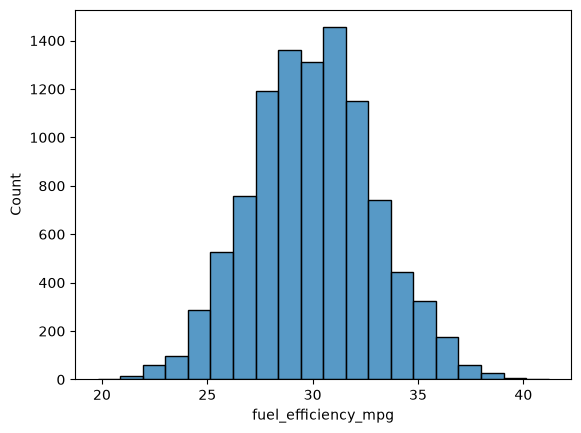

In [5]:
sns.histplot(df.fuel_efficiency_mpg, bins=20)

### Question 1: Column with the missing values

In [6]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

Answer: "horsepower"

======================================================

### Question 2: What's the median (50% percentile) for variable ​'horsepower'​?

In [7]:
median_hp = df[["horsepower"]].median()
print(median_hp)

horsepower    254.0
dtype: float64


Answer: 254.0

======================================================

### Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This
  keeps the imputation difference visible in this release.
* Which option gives better RMSE?

Options:

- With 0
- With mean
- Both are equally good

In [8]:
df_unmodified = df.copy()

In [9]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [10]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

Filling NaN with Zero (0)

In [11]:
X_train = df_train[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]].fillna(0).values
y_train = df_train["fuel_efficiency_mpg"].values

In [12]:
w0, w = train_linear_regression(X_train, y_train)

In [13]:
y_train_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

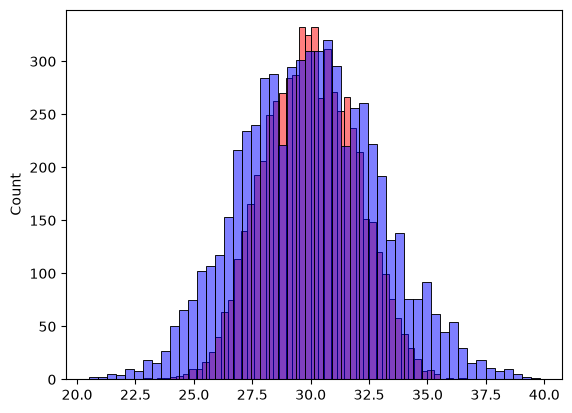

In [14]:
sns.histplot(y_train_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [15]:
X_val = df_val[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]].fillna(0).values
y_val = df_val["fuel_efficiency_mpg"].values
y_val_pred = w0 + X_val.dot(w)
score_val = rmse(y_val, y_val_pred)
print("Validation RMSE:", round(score_val, 3))

Validation RMSE: 2.205


Filling NaN with Mean

In [16]:
mean_hp = df[["horsepower"]].mean()
mean_hp

horsepower    254.446016
dtype: float64

In [17]:
X_train = df_train[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]].fillna(mean_hp).values
y_train = df_train["fuel_efficiency_mpg"].values

X_val = df_val[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]].fillna(mean_hp).values
y_val = df_val["fuel_efficiency_mpg"].values

w0, w = train_linear_regression(X_train, y_train)

y_val_pred = w0 + X_val.dot(w)
score_val_fill_mean = rmse(y_val, y_val_pred)
print("Validation RMSE with mean fill:", round(score_val_fill_mean, 3))

Validation RMSE with mean fill: 2.202


Answer: With Mean

======================================================

### Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0.
* Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 4 decimal digits. This keeps the small but real
  regularization differences visible instead of turning several choices into a tie.
* Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0
- 0.01
- 0.1
- 1
- 5
- 10
- 100

In [18]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def prepare_X(df):
    df_num = df[["engine_displacement", "horsepower", "vehicle_weight", "model_year"]]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [19]:
X_train = prepare_X(df_train)
y_train = df_train["fuel_efficiency_mpg"].values
X_val = prepare_X(df_val)
y_val = df_val["fuel_efficiency_mpg"].values
rmse_values = []
r_value = []

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_val_pred = w0 + X_val.dot(w)
    score_val = rmse(y_val, y_val_pred)
    print("Validation RMSE with r = {}: {}".format(r, round(score_val, 4)))
    rmse_values.append(score_val)
    r_value.append(r)

min_rmse = min(rmse_values)
best_r = r_value[rmse_values.index(min_rmse)]
print("Minimum RMSE:", round(min_rmse, 4))
print("Best r:", best_r)


Validation RMSE with r = 0: 2.2053
Validation RMSE with r = 0.01: 2.2058
Validation RMSE with r = 0.1: 2.2241
Validation RMSE with r = 1: 2.3492
Validation RMSE with r = 5: 2.4094
Validation RMSE with r = 10: 2.4195
Validation RMSE with r = 100: 2.4292
Minimum RMSE: 2.2053
Best r: 0


Answer: Smallest r = 0

======================================================

### Question 5

* We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
* Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
* For each seed, do the train/validation/test split with 60%/20%/20% distribution.
* Fill the missing values with 0 and train a model without regularization.
* For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
* What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
* Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029
- 0.036

In [20]:
seed_list = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmse_values = []

for seed in seed_list:
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    X_train = prepare_X(df_train)
    y_train = df_train["fuel_efficiency_mpg"].values
    X_val = prepare_X(df_val)
    y_val = df_val["fuel_efficiency_mpg"].values
    # X_test = prepare_X(df_test)
    # y_test = df_test["fuel_efficiency_mpg"].values

    w0, w = train_linear_regression(X_train, y_train)
    y_val_pred = w0 + X_val.dot(w)
    score_val = rmse(y_val, y_val_pred)
    print(f"Seed: {seed}, RMSE: {score_val}")
    rmse_values.append(score_val)

std_dev_rmse = np.std(rmse_values)
print("Standard deviation of RMSE across different seeds:", round(std_dev_rmse, 3))

Seed: 0, RMSE: 2.239204143046126
Seed: 1, RMSE: 2.2021128210838845
Seed: 2, RMSE: 2.1634197787530947
Seed: 3, RMSE: 2.2043588768539224
Seed: 4, RMSE: 2.2018800943311554
Seed: 5, RMSE: 2.2457851509085134
Seed: 6, RMSE: 2.2697212079524043
Seed: 7, RMSE: 2.190794599933443
Seed: 8, RMSE: 2.216611201686444
Seed: 9, RMSE: 2.2070365928178957
Standard deviation of RMSE across different seeds: 0.029


Answer: Standard deviation of RMSE across different seeds: 0.029

======================================================

### Question 6

* Split the dataset like previously, use seed 9.
* Combine train and validation datasets.
* Fill the missing values with 0 and train a model with `r=0.001`.
* What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236
- 22.10
- 221.0

In [22]:
seed = 9

n = len(df)
n_test = int(n * 0.2)
n_val = int(n * 0.2)
n_train = n - n_test - n_val

np.random.seed(seed)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values

X_full_train = prepare_X(df_full_train)
y_full_train = np.concatenate([y_train, y_val])

X_test = prepare_X(df_test)
y_test = df_test["fuel_efficiency_mpg"].values

w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
y_test_pred = w0 + X_test.dot(w)
score_test = rmse(y_test, y_test_pred)
print("Test RMSE:", round(score_test, 3))


Test RMSE: 2.236


Answer: Test RMSE = 2.236